# 📊 The Master Statistics Handbook: Probability Distribution Functions (PMF, PDF, CDF) & Density Estimation
### *From Theoretical Foundations to Machine Learning Feature Engineering, Kernel Density Estimation & Distribution Diagnostics*

> **Purpose:** A complete, production-grade statistical reference and interview masterclass designed for Data Scientists and Machine Learning Engineers. Every module translates theoretical formalisms into **30-second interview pitches**, **intuitive mental models**, **executable Python demonstrations**, and **critical real-world failure modes**.

---

## 📑 Complete Table of Contents
1. [Module 1: Random Variables (Discrete vs. Continuous)](#module-1)
2. [Module 2: Probability Distributions & The Axioms of Probability](#module-2)
3. [Module 3: Probability Distribution Functions: PMF vs. PDF vs. CDF](#module-3)
4. [Module 4: Probability Mass Function (PMF) & The Two-Dice Experiment](#module-4)
5. [Module 5: Cumulative Distribution Function (CDF) of Discrete Variables](#module-5)
6. [Module 6: Probability Density Function (PDF) & The Continuous Paradox](#module-6)
7. [Module 7: Cumulative Distribution Function (CDF) of Continuous Variables](#module-7)
8. [Module 8: The Need for Density Estimation (Parametric vs. Non-Parametric)](#module-8)
9. [Module 9: Kernel Density Estimation (KDE) Deep Dive & Bandwidth Tuning](#module-9)
10. [Module 10: Practical ML Use Case 1: Iris Dataset (Feature Discriminability & Class Separation)](#module-10)
11. [Module 11: Practical ML Use Case 2: Titanic Dataset (Diagnostics, Skewness, Kurtosis & Outliers)](#module-11)
12. [Module 12: Master Interview Cheat Sheet & Rapid-Fire Technical Q&A](#module-12)

---



<a id="module-1"></a>
# Module 1: Random Variables (Discrete vs. Continuous)

---

### 🎯 The Classic Interview Question
> **"What is a Random Variable? Why is it mathematically a function rather than a variable? Distinguish between Discrete and Continuous Random Variables with real-world ML examples."**

---

### 💡 The 30-Second Interview Answer
> *"A **Random Variable (RV)** is not a single number, nor is it 'random' in its execution. Mathematically, it is a **deterministic function** that maps outcomes from a sample space $\Omega$ of a random experiment to real numbers $\mathbb{R}$:  
> $$X: \Omega \to \mathbb{R}$$
> 
> Random variables are categorized into two fundamental types based on their **support** (range of possible values):
> 1. **Discrete Random Variable:** Takes on a **countable** number of distinct values (finite or countably infinite). Examples in ML: Number of website conversions, customer churn label ($y \in \{0, 1\}$), vocabulary token IDs in NLP.
> 2. **Continuous Random Variable:** Takes on an **uncountably infinite** continuum of values within an interval. Examples in ML: Server latency, customer lifetime value, house prices, neural network training loss."*

---

### 🧠 Deep Dive: The Mathematical Formalism

In formal probability theory, a random experiment is defined by a probability space $(\Omega, \mathcal{F}, P)$, where:
* $\Omega$ is the **Sample Space** (the set of all possible experimental outcomes).
* $\mathcal{F}$ is the **$\sigma$-algebra** (the collection of observable events).
* $P$ is the **Probability Measure** assigning a probability $P(E) \in [0, 1]$ to every event $E \in \mathcal{F}$.

A random variable $X$ acts as a bridge converting abstract qualitative outcomes into quantitative numbers:

```
    [ Sample Space Ω ]                [ Real Line ℝ ]
   ┌───────────────────┐              ┌───────────────────┐
   │  Outcome ω₁ (Win) │ ─── X(ω) ──► │  Value: +1.0      │
   │  Outcome ω₂ (Loss)│ ─── X(ω) ──► │  Value:  0.0      │
   │  Outcome ω₃ (Draw)│ ─── X(ω) ──► │  Value:  0.5      │
   └───────────────────┘              └───────────────────┘
```

#### Notation Conventions:
* **Capital letter $X$:** Represents the random variable (the *rule* or *function*).
* **Lowercase letter $x$:** Represents a specific realized value or observation that $X$ can take.
* **$P(X = x)$:** Shorthand for $P(\{\omega \in \Omega : X(\omega) = x\})$, meaning "the probability that the outcome $\omega$ maps to the numerical value $x$."

---

### ⚖️ Discrete vs. Continuous Comparison Matrix

| Property | Discrete Random Variable | Continuous Random Variable |
| :--- | :--- | :--- |
| **Support $\mathcal{X}$** | Countable (Finite or Countably Infinite) | Uncountable Continuum (Intervals in $\mathbb{R}$) |
| **Probability Function** | Probability Mass Function (PMF): $p(x) = P(X = x)$ | Probability Density Function (PDF): $f(x)$ |
| **Single-Point Probability** | $P(X = x) \ge 0$ (Can be non-zero) | $P(X = x) = 0$ (Always zero for any exact point!) |
| **Interval Probability** | $\sum_{a \le x_i \le b} p(x_i)$ | $\int_a^b f(x) dx$ (Area under curve) |
| **Cumulative Distribution** | Step / Staircase Function | Continuous, Smooth Curve |
| **Total Probability Axiom** | $\sum_{x \in \mathcal{X}} p(x) = 1$ | $\int_{-\infty}^{\infty} f(x) dx = 1$ |
| **ML Use Cases** | Target labels, count features, click rates | Feature scaling, regression targets, loss surfaces |

---

### ⚠️ Common Pitfalls & Senior Interview Traps
1. **The "Infinite = Continuous" Trap:** Many candidates mistakenly assume that if a random variable can take infinitely many values, it must be continuous. **False!** A **Poisson random variable** (number of support tickets per hour: $k \in \{0, 1, 2, \dots\}$) or a **Geometric random variable** (coin tosses until first heads) has an **infinitely countable** support, yet is **strictly discrete**.
2. **Mixed Random Variables:** Real-world ML datasets often contain *mixed random variables*. For example, daily rainfall amount: exactly $0$ mm on dry days with a discrete probability mass ($P(X = 0) = 0.6$), but a continuous distribution for positive rainfall ($X > 0$). Failing to account for this leads to poor zero-inflated modeling.



<a id="module-2"></a>
# Module 2: Probability Distributions & The Axioms of Probability

---

### 🎯 The Classic Interview Question
> **"What is a Probability Distribution? What mathematical conditions (axioms) must every valid probability distribution satisfy, and how does this relate to Loss Functions in Machine Learning?"**

---

### 💡 The 30-Second Interview Answer
> *"A **Probability Distribution** is the complete mathematical rule, table, or equation that specifies how probability mass or density is apportioned across all possible values of a random variable.  
> Every valid probability distribution is governed by **Kolmogorov’s Three Axioms of Probability**:
> 1. **Non-Negativity:** For any event $E$, $P(E) \ge 0$.
> 2. **Normalization (Certainty):** The probability of the entire sample space is unity: $P(\Omega) = 1$.
> 3. **Countable Additivity:** For mutually disjoint events $E_1, E_2, \dots$, $P\left(\bigcup_{i=1}^{\infty} E_i\right) = \sum_{i=1}^{\infty} P(E_i)$.
> 
> In Machine Learning, models output predicted probability distributions (e.g., via Softmax). We evaluate them using **Cross-Entropy Loss** or **Kullback-Leibler (KL) Divergence**, which quantifies the information-theoretic distance between the true data distribution $P$ and the model's predicted distribution $Q$."*

---

### 🔬 Deep Dive: Theoretical Foundations & Moments

A probability distribution completely characterizes the stochastic behavior of $X$. Beyond its functional form, a distribution is summarized by its **moments**:

1. **First Raw Moment (Expected Value / Center of Mass):**
   $$\mathbb{E}[X] = \mu = \begin{cases} \sum_x x \cdot p(x) & \text{(Discrete)} \\[6pt] \int_{-\infty}^\infty x \cdot f(x) dx & \text{(Continuous)} \end{cases}$$
2. **Second Central Moment (Variance / Dispersion):**
   $$\text{Var}(X) = \sigma^2 = \mathbb{E}[(X - \mu)^2] = \mathbb{E}[X^2] - (\mathbb{E}[X])^2$$
3. **Third Standardized Moment (Skewness / Asymmetry):**
   $$\tilde{\mu}_3 = \mathbb{E}\left[\left(\frac{X - \mu}{\sigma}\right)^3\right]$$
4. **Fourth Standardized Moment (Kurtosis / Tail Weight):**
   $$\tilde{\mu}_4 = \mathbb{E}\left[\left(\frac{X - \mu}{\sigma}\right)^4\right]$$

---

### 💼 Machine Learning Connection: Softmax & Cross-Entropy
When training a multi-class neural network (e.g., classifying an image into Cat, Dog, or Bird), the raw output layer produces unbounded logits $z = [z_1, z_2, z_3]$.
To convert logits into a valid Kolmogorov-compliant probability distribution, we apply the **Softmax function**:
$$p_i = \frac{e^{z_i}}{\sum_{j=1}^K e^{z_j}}$$
* Non-negativity satisfied: $e^{z_i} > 0 \implies p_i > 0$.
* Normalization satisfied: $\sum_{i=1}^K p_i = \frac{\sum e^{z_i}}{\sum e^{z_j}} = 1$.



<a id="module-3"></a>
# Module 3: Probability Distribution Functions: PMF vs. PDF vs. CDF

---

### 🎯 The Classic Interview Question
> **"What are PMF, PDF, and CDF? Can a PDF value be greater than 1? Can a PMF or CDF value be greater than 1? What does the value of each function actually represent?"**

---

### 💡 The 30-Second Interview Answer
> *"These three functions define how probabilities are distributed:
> 1. **PMF (Probability Mass Function, $p(x)$):** Applies strictly to **discrete** variables. The value $p(x)$ is an **actual probability** ($P(X = x)$). Values are strictly bounded: $0 \le p(x) \le 1$.
> 2. **PDF (Probability Density Function, $f(x)$):** Applies strictly to **continuous** variables. The value $f(x)$ is **not a probability**; it is a **probability density** (probability per unit of $x$). It **can exceed 1** (e.g., a uniform distribution on $[0, 0.1]$ has $f(x) = 10$). Probability is found by integrating over an interval: $P(a \le X \le b) = \int_a^b f(x) dx$.
> 3. **CDF (Cumulative Distribution Function, $F(x)$):** Applies to **both** discrete and continuous variables. It gives the cumulative probability up to $x$: $F(x) = P(X \le x)$. Values are strictly bounded: $0 \le F(x) \le 1$, and $F(x)$ is monotonically non-decreasing."*

---

### 📊 The Ultimate Distribution Functions Comparison Matrix

| Dimension | Probability Mass Function (PMF) | Probability Density Function (PDF) | Cumulative Distribution Function (CDF) |
| :--- | :--- | :--- | :--- |
| **Symbol** | $p(x)$ or $P(X = x)$ | $f(x)$ | $F(x) = P(X \le x)$ |
| **Applicable Domain** | Discrete Random Variables | Continuous Random Variables | **Both** Discrete & Continuous |
| **Value Meaning** | Exact probability of outcome $x$ | Relative density / likelihood rate at $x$ | Cumulative probability from $-\infty$ up to $x$ |
| **Output Range** | $[0, 1]$ (Strictly bounded) | $[0, \infty)$ (**Can exceed 1!**) | $[0, 1]$ (Strictly bounded) |
| **Single Point $P(X=x)$** | Equal to $p(x)$ | **Exactly 0** | $F(x) - F(x^-)$ (Zero if continuous) |
| **Interval Probability** | $\sum_{x \in [a, b]} p(x)$ | $\int_a^b f(x) dx$ | $F(b) - F(a)$ |
| **Total Normalization** | $\sum_{x} p(x) = 1$ | $\int_{-\infty}^{\infty} f(x) dx = 1$ | $\lim_{x \to \infty} F(x) = 1$ |
| **Calculus Relationship** | Difference of CDF steps | Derivative of continuous CDF: $f(x) = F'(x)$ | Integral of PDF: $F(x) = \int_{-\infty}^x f(t) dt$ |
| **Visual Appearance** | Isolated spikes or bar charts | Continuous, smooth curve | Stepwise staircase (discrete) or smooth S-curve (continuous) |



<a id="module-4"></a>
# Module 4: Probability Mass Function (PMF) & The Two-Dice Experiment

---

### 🎯 The Classic Interview Question
> **"Define a PMF mathematically. What are its two core constraints? How do you calculate the PMF of the sum of two rolling dice, and why does it peak at 7?"**

---

### 💡 The 30-Second Interview Answer
> *"A **Probability Mass Function (PMF)**, denoted $p_X(x)$, assigns a probability to each distinct value $x$ that a discrete random variable $X$ can assume:  
> $$p_X(x) = P(X = x)$$  
> It must satisfy two non-negotiable conditions:
> 1. **Non-negativity:** $p_X(x) \ge 0$ for all $x \in \mathbb{R}$.
> 2. **Sum to Unity:** $\sum_{x} p_X(x) = 1$.
> 
> When rolling two fair 6-sided dice, the sample space contains $6 \times 6 = 36$ equally likely ordered pairs. The sum $S = A + B$ ranges from $2$ to $12$. The sum of 7 has the highest number of combinations (6 pairs: $(1,6), (2,5), (3,4), (4,3), (5,2), (6,1)$), giving $P(S = 7) = \frac{6}{36} \approx 16.67\%$, forming a symmetric triangular PMF."*

---

### 🎲 Deep Dive: Two-Dice Analytical Derivation

Let $A, B \in \{1, 2, 3, 4, 5, 6\}$ with $P(A=a) = \frac{1}{6}$ and $P(B=b) = \frac{1}{6}$. The sum $S = A + B$:

| Sum ($s$) | Combinations $(a, b)$ | Total Count | Exact Theoretical PMF $P(S = s)$ | Decimal |
| :---: | :--- | :---: | :---: | :---: |
| **2** | $(1,1)$ | 1 | $1/36$ | $0.0278$ |
| **3** | $(1,2), (2,1)$ | 2 | $2/36$ | $0.0556$ |
| **4** | $(1,3), (2,2), (3,1)$ | 3 | $3/36$ | $0.0833$ |
| **5** | $(1,4), (2,3), (3,2), (4,1)$ | 4 | $4/36$ | $0.1111$ |
| **6** | $(1,5), (2,4), (3,3), (4,2), (5,1)$ | 5 | $5/36$ | $0.1389$ |
| **7** | $(1,6), (2,5), (3,4), (4,3), (5,2), (6,1)$ | 6 | $6/36$ | **$0.1667$** |
| **8** | $(2,6), (3,5), (4,4), (5,3), (6,2)$ | 5 | $5/36$ | $0.1389$ |
| **9** | $(3,6), (4,5), (5,4), (6,3)$ | 4 | $4/36$ | $0.1111$ |
| **10** | $(4,6), (5,5), (6,4)$ | 3 | $3/36$ | $0.0833$ |
| **11** | $(5,6), (6,5)$ | 2 | $2/36$ | $0.0556$ |
| **12** | $(6,6)$ | 1 | $1/36$ | $0.0278$ |
| **Total** | | **36** | **36/36** | **1.0000** |

Below, we simulate 10,000 independent two-dice rolls in Python, compute the normalized empirical PMF, and compare it with theory.



--- Empirical Probability Mass Function (PMF) ---
2     0.0270
3     0.0540
4     0.0816
5     0.1094
6     0.1359
7     0.1704
8     0.1392
9     0.1116
10    0.0838
11    0.0560
12    0.0311
Name: count, dtype: float64

--- Empirical Cumulative Distribution Function (CDF) ---
2     0.0270
3     0.0810
4     0.1626
5     0.2720
6     0.4079
7     0.5783
8     0.7175
9     0.8291
10    0.9129
11    0.9689
12    1.0000
Name: count, dtype: float64


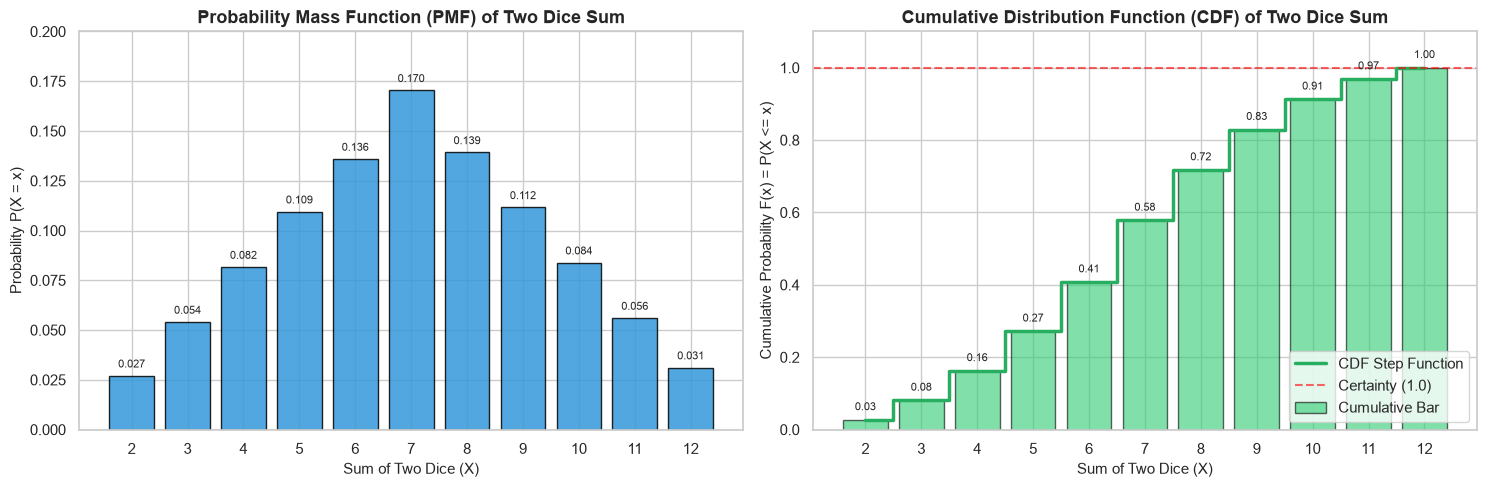

In [1]:
# ==============================================================================
# DEMONSTRATION 1: The Two-Dice Sum Experiment (PMF and CDF)
# ==============================================================================
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual aesthetic
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11

# Generating the data for analysis: 10,000 rolls of two fair 6-sided dice
random.seed(42)
L = []
for i in range(10000):
    a = random.randint(1, 6)
    b = random.randint(1, 6)
    L.append(a + b)

# Normalizing and sorting to compute empirical PMF
s = (pd.Series(L).value_counts() / pd.Series(L).value_counts().sum()).sort_index()
print("--- Empirical Probability Mass Function (PMF) ---")
print(s)

# Cumulative sum to compute empirical CDF
cdf_discrete = np.cumsum(s)
print("\n--- Empirical Cumulative Distribution Function (CDF) ---")
print(cdf_discrete)

# Visualizing PMF and CDF side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot PMF Bar Chart
bars = axes[0].bar(s.index, s.values, color='#3498db', edgecolor='black', alpha=0.85)
axes[0].set_title('Probability Mass Function (PMF) of Two Dice Sum', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Sum of Two Dice (X)', fontsize=11)
axes[0].set_ylabel('Probability P(X = x)', fontsize=11)
axes[0].set_xticks(range(2, 13))
axes[0].set_ylim(0, 0.20)
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 0.003, f'{yval:.3f}', ha='center', va='bottom', fontsize=8)

# Plot CDF Bar & Step Chart
axes[1].bar(cdf_discrete.index, cdf_discrete.values, color='#2ecc71', edgecolor='black', alpha=0.6, label='Cumulative Bar')
axes[1].step(cdf_discrete.index, cdf_discrete.values, where='mid', color='#27ae60', linewidth=2.5, label='CDF Step Function')
axes[1].set_title('Cumulative Distribution Function (CDF) of Two Dice Sum', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Sum of Two Dice (X)', fontsize=11)
axes[1].set_ylabel('Cumulative Probability F(x) = P(X <= x)', fontsize=11)
axes[1].set_xticks(range(2, 13))
axes[1].set_ylim(0, 1.1)
axes[1].axhline(1.0, color='red', linestyle='--', alpha=0.6, label='Certainty (1.0)')
for idx, val in cdf_discrete.items():
    axes[1].text(idx, val + 0.02, f'{val:.2f}', ha='center', va='bottom', fontsize=8)
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()



<a id="module-5"></a>
# Module 5: Cumulative Distribution Function (CDF) of Discrete Variables

---

### 🎯 The Classic Interview Question
> **"What does the Cumulative Distribution Function (CDF) of a discrete random variable look like? How do you compute interval probabilities $P(a < X \le b)$ using the CDF?"**

---

### 💡 The 30-Second Interview Answer
> *"For a discrete random variable, the **CDF** $F_X(x)$ represents the probability that $X$ takes a value less than or equal to $x$:
> $$F_X(x) = P(X \le x) = \sum_{x_i \le x} p_X(x_i)$$
> 
> Visually, the discrete CDF is a **staircase step function**:
> * It is constant between sample points.
> * At each valid outcome $x_i$, it takes an instantaneous vertical jump equal to the probability mass $p_X(x_i)$.
> * It is **right-continuous** (càdlàg): the value at the step jump includes the point mass.
> 
> To find the probability that $X$ falls strictly in the half-open interval $(a, b]$:
> $$P(a < X \le b) = F(b) - F(a)$$
> This subtraction eliminates the need to sum individual probabilities across hundreds of discrete outcomes."*

---

### 🪜 Mathematical Properties of Any CDF
1. **Boundedness:** $0 \le F(x) \le 1$ for all $x \in \mathbb{R}$.
2. **Monotonicity:** If $x_1 < x_2$, then $F(x_1) \le F(x_2)$ (it can never decrease).
3. **Asymptotic Limits:**
   $$\lim_{x \to -\infty} F(x) = 0 \quad \text{and} \quad \lim_{x \to +\infty} F(x) = 1$$
4. **Right-Continuity:** $\lim_{h \to 0^+} F(x + h) = F(x)$.



<a id="module-6"></a>
# Module 6: Probability Density Function (PDF) & The Continuous Paradox

---

### 🎯 The Classic Interview Question
> **"Why is the probability of picking an exact value from a continuous distribution equal to zero: $P(X = c) = 0$? If every single point has zero probability, how can the total probability be 1? Can a PDF value exceed 1?"**

---

### 💡 The 30-Second Interview Answer
> *"For a continuous random variable, the support contains an **uncountably infinite** number of points. If each point had even an infinitesimal non-zero probability $\epsilon > 0$, the sum of probabilities would diverge to $\infty$, violating Kolmogorov's second axiom (total probability = 1). Therefore, by calculus:  
> $$P(X = c) = \lim_{\Delta x \to 0} \int_c^{c + \Delta x} f(x) dx = 0$$
> 
> In continuous probability, probability is defined over **intervals**, represented by the **area under the PDF curve**:  
> $$P(a \le X \le b) = \int_a^b f(x) dx$$
> 
> **Can a PDF exceed 1? YES!** A PDF represents probability *density* (probability per unit of $x$), not probability itself. For example, for a uniform distribution $X \sim \text{Uniform}(0, 0.1)$, the density is constant at $f(x) = \frac{1}{0.1 - 0} = 10$ across $[0, 0.1]$. The only constraint is that the total integral must equal 1: $\int_{-\infty}^\infty f(x) dx = 1$."*

---

### 🔬 Deep Dive: Density vs. Probability

A common conceptual hurdle in statistics is conflating **Probability** with **Probability Density**:

```
           f(x) ▲
  PDF Rate: 10  │ ┌──────────────┐
                │ │ Area = 1.0   │   Height = 10 (Density)
                │ │              │   Width  = 0.1
             0  └─┴──────────────┴──────► x
                  0             0.1
```

* **Physical Analogy:** Consider the mass of a solid rod. A single point on the rod has a physical thickness of 0, so its mass at an exact point is 0. However, the rod has a non-zero **linear mass density** $\rho(x) = \frac{dm}{dx}$ (in $\text{kg/m}$). To find the actual mass, you must integrate density over a length segment: $m = \int_a^b \rho(x) dx$.
* **Mathematical Definition:** The PDF is the derivative of the Cumulative Distribution Function (CDF):
  $$f(x) = \frac{d}{dx} F(x) = \lim_{\Delta x \to 0} \frac{P(x \le X \le x + \Delta x)}{\Delta x}$$
  Therefore:
  $$P(x \le X \le x + dx) \approx f(x) \cdot dx$$

---

### 💼 Machine Learning Applications
1. **Gaussian Naive Bayes:** Computes class likelihoods by evaluating continuous feature values in a Gaussian PDF:
   $$P(x_i \mid y) = \frac{1}{\sqrt{2\pi \sigma_y^2}} \exp\left(-\frac{(x_i - \mu_y)^2}{2\sigma_y^2}\right)$$
2. **Maximum Likelihood Estimation (MLE):** Parameter fitting in continuous regression maximizes the product of PDF evaluations (joint likelihood $\mathcal{L}(\theta) = \prod f(x_i; \theta)$) or log-likelihood.



<a id="module-7"></a>
# Module 7: Cumulative Distribution Function (CDF) of Continuous Variables

---

### 🎯 The Classic Interview Question
> **"What is the continuous CDF, how is it related to the PDF via calculus, and why is the Empirical Cumulative Distribution Function (ECDF) often superior to histograms in Exploratory Data Analysis?"**

---

### 💡 The 30-Second Interview Answer
> *"The continuous **CDF** $F_X(x)$ accumulates the probability density from $-\infty$ up to $x$:  
> $$F_X(x) = P(X \le x) = \int_{-\infty}^x f(t) dt$$  
> By the Fundamental Theorem of Calculus, the PDF is simply the rate of change (derivative) of the CDF: $f(x) = \frac{d}{dx}F(x)$.
> 
> Unlike a histogram, which is heavily distorted by arbitrary choices of **bin width** and **bin origins**, the **Empirical CDF (ECDF)**:
> 1. Requires **zero hyperparameters or binning**.
> 2. Preserves every single data point faithfully.
> 3. Converges uniformly to the true population CDF as $n \to \infty$ by the **Glivenko-Cantelli Theorem** (the 'Fundamental Theorem of Statistics')."*

---

### 📈 Continuous CDF Key Properties & Applications

1. **Smooth Monotonic S-Curve:** For unimodal distributions like the Gaussian, the CDF forms a smooth sigmoidal S-curve bounded strictly in $[0, 1]$.
2. **Quantiles and Percentiles (Inverse CDF):**
   The **Quantile Function** $Q(p) = F^{-1}(p)$ for $p \in (0, 1)$ returns the exact data threshold below which a fraction $p$ of the data lies.
   * $p = 0.50 \implies$ Median
   * $p = 0.25, 0.75 \implies$ 1st and 3rd Quartiles ($Q_1, Q_3$)
   * Financial Risk: Value at Risk (VaR) is computed directly as $F^{-1}(\alpha)$.
3. **Hypothesis Testing (Kolmogorov-Smirnov Test):**
   The two-sample KS-test compares two empirical CDFs $\hat{F}_1(x)$ and $\hat{F}_2(x)$ by finding their maximum vertical distance:
   $$D = \sup_x |\hat{F}_1(x) - \hat{F}_2(x)|$$
   If $D$ exceeds a critical threshold, we reject the null hypothesis that the samples come from the same distribution.



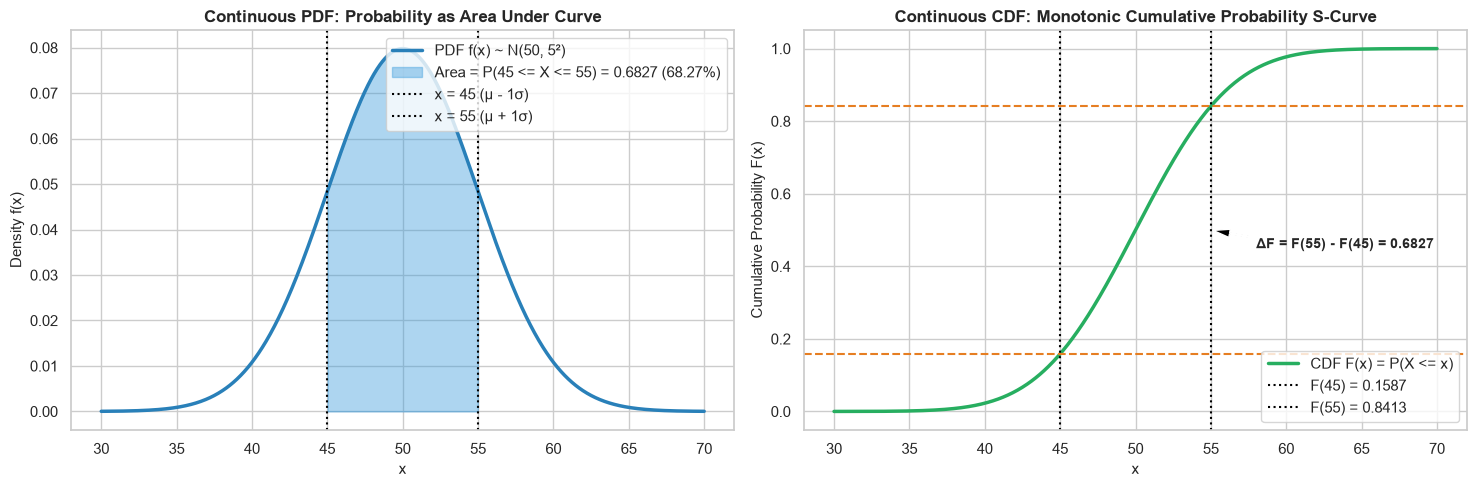

P(X <= 55) = F(55) = 0.8413
P(X <= 45) = F(45) = 0.1587
P(45 <= X <= 55) = F(55) - F(45) = 0.6827


In [2]:
# ==============================================================================
# DEMONSTRATION 2: Continuous PDF vs Continuous CDF & Interval Integration
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Theoretical Normal Distribution: N(50, 5^2)
mu, sigma = 50, 5
x_axis = np.linspace(30, 70, 1000)
pdf_vals = norm.pdf(x_axis, loc=mu, scale=sigma)
cdf_vals = norm.cdf(x_axis, loc=mu, scale=sigma)

# Target interval: P(45 <= X <= 55) -> 1 standard deviation around mean
lower_bound, upper_bound = 45, 55
prob_interval = norm.cdf(upper_bound, mu, sigma) - norm.cdf(lower_bound, mu, sigma)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot PDF with shaded area
axes[0].plot(x_axis, pdf_vals, color='#2980b9', linewidth=2.5, label=f'PDF f(x) ~ N({mu}, {sigma}²)')
axes[0].fill_between(x_axis, pdf_vals, where=(x_axis >= lower_bound) & (x_axis <= upper_bound),
                     color='#3498db', alpha=0.4, label=f'Area = P(45 <= X <= 55) = {prob_interval:.4f} (68.27%)')
axes[0].axvline(lower_bound, color='black', linestyle=':', label='x = 45 (μ - 1σ)')
axes[0].axvline(upper_bound, color='black', linestyle=':', label='x = 55 (μ + 1σ)')
axes[0].set_title('Continuous PDF: Probability as Area Under Curve', fontsize=12, fontweight='bold')
axes[0].set_xlabel('x', fontsize=11)
axes[0].set_ylabel('Density f(x)', fontsize=11)
axes[0].legend(loc='upper right')

# Plot continuous CDF
axes[1].plot(x_axis, cdf_vals, color='#27ae60', linewidth=2.5, label=f'CDF F(x) = P(X <= x)')
axes[1].axvline(lower_bound, color='black', linestyle=':', label=f'F(45) = {norm.cdf(45, mu, sigma):.4f}')
axes[1].axvline(upper_bound, color='black', linestyle=':', label=f'F(55) = {norm.cdf(55, mu, sigma):.4f}')
axes[1].axhline(norm.cdf(45, mu, sigma), color='#e67e22', linestyle='--')
axes[1].axhline(norm.cdf(55, mu, sigma), color='#e67e22', linestyle='--')
axes[1].annotate(f'ΔF = F(55) - F(45) = {prob_interval:.4f}',
                 xy=(55, 0.5), xytext=(58, 0.45),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
                 fontsize=10, fontweight='bold')
axes[1].set_title('Continuous CDF: Monotonic Cumulative Probability S-Curve', fontsize=12, fontweight='bold')
axes[1].set_xlabel('x', fontsize=11)
axes[1].set_ylabel('Cumulative Probability F(x)', fontsize=11)
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

print(f"P(X <= 55) = F(55) = {norm.cdf(55, mu, sigma):.4f}")
print(f"P(X <= 45) = F(45) = {norm.cdf(45, mu, sigma):.4f}")
print(f"P(45 <= X <= 55) = F(55) - F(45) = {norm.cdf(55, mu, sigma) - norm.cdf(45, mu, sigma):.4f}")



<a id="module-8"></a>
# Module 8: The Need for Density Estimation (Parametric vs. Non-Parametric)

---

### 🎯 The Classic Interview Question
> **"What is Density Estimation? Compare Parametric vs. Non-Parametric density estimation in terms of assumptions, computational complexity, sample efficiency, and the bias-variance tradeoff."**

---

### 💡 The 30-Second Interview Answer
> *"In real-world data science, we never observe the true population PDF $f(x)$; we only have a finite observed sample $\{x_1, x_2, \dots, x_n\}$. **Density Estimation** is the inverse problem of reconstructing the continuous generative distribution from this finite sample.
> 
> We have two primary paradigms:
> 1. **Parametric Estimation:** We assume the data comes from a known mathematical family (e.g., Gaussian $\mathcal{N}(\mu, \sigma^2)$) and estimate a fixed set of parameters (e.g., $\hat{\mu} = \bar{x}, \hat{\sigma} = s$).  
>    * **Pros:** Fast, highly sample-efficient, low variance.  
>    * **Cons:** High bias if the parametric assumption is wrong (e.g., fitting a Gaussian onto bimodal customer data).
> 2. **Non-Parametric Estimation:** We make **no rigid distributional assumptions** and let the data dictate the distribution's shape (e.g., Kernel Density Estimation).  
>    * **Pros:** Highly flexible; easily captures multimodality, skewness, and heavy tails.  
>    * **Cons:** Requires more data, sensitive to bandwidth tuning, computationally heavier."*

---

### ⚖️ Parametric vs. Non-Parametric Comparison Matrix

| Dimension | Parametric Approach | Non-Parametric Approach (KDE) |
| :--- | :--- | :--- |
| **Model Assumption** | Rigid family assumed (Normal, Poisson, Gamma) | Free-form / Minimal smoothness assumptions |
| **Parameters** | Fixed, finite number of parameters (e.g., $\mu, \sigma$) | Scales with data points $n$ (memory-based) |
| **Sample Efficiency** | High (converges with small sample sizes) | Moderate to Low (requires more data to stabilize) |
| **Bias-Variance** | Low Variance / High Bias (if model is mis-specified) | Low Bias / High Variance (sensitive to bandwidth) |
| **Multimodality** | Fails completely unless mixture models are used | Naturally discovers bimodal and multimodal clusters |
| **Inference Cost** | $\mathcal{O}(1)$ constant time | $\mathcal{O}(n)$ time per query point |
| **High Dimensions** | Scales well if independence is assumed | Suffers from the **Curse of Dimensionality** ($d > 3$) |

---

### 🔬 Mathematical Formulation: Parametric Maximum Likelihood
For a Gaussian assumption $X \sim \mathcal{N}(\mu, \sigma^2)$, the joint likelihood of independent observations is:
$$\mathcal{L}(\mu, \sigma^2) = \prod_{i=1}^n \frac{1}{\sqrt{2\pi \sigma^2}} \exp\left(-\frac{(x_i - \mu)^2}{2\sigma^2}\right)$$
Maximizing the log-likelihood $\ln \mathcal{L}$ yields the sample estimators:
$$\hat{\mu}_{MLE} = \frac{1}{n}\sum_{i=1}^n x_i = \bar{x}, \qquad \hat{\sigma}^2_{MLE} = \frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})^2$$



Sample Mean: 50.0967
Sample Std Dev: 4.8936


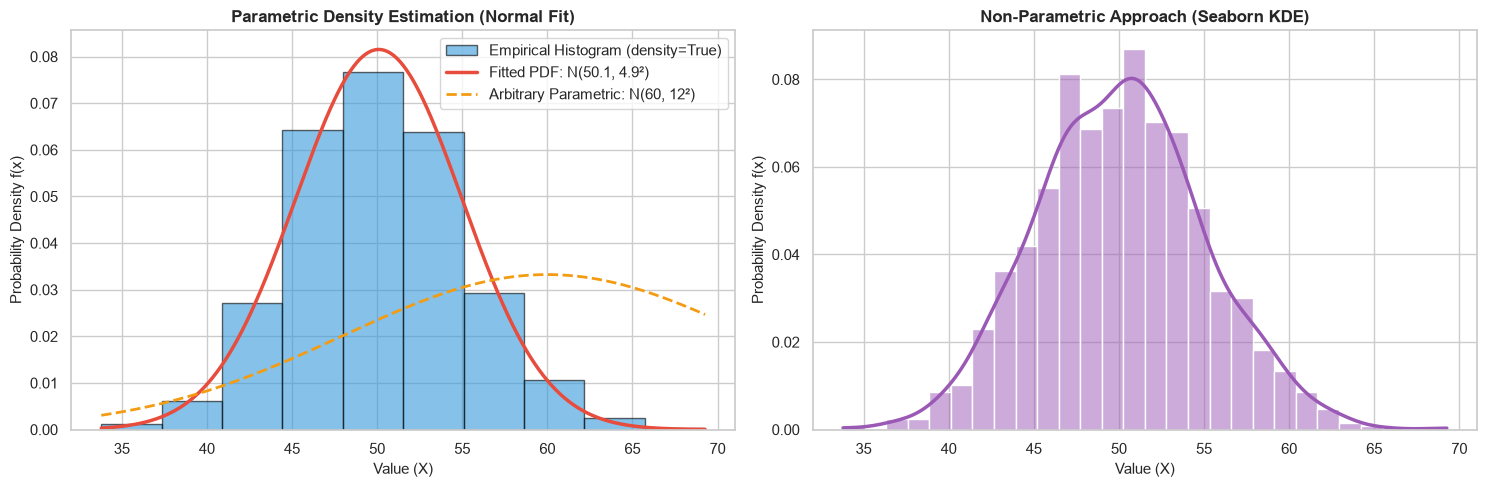

In [3]:
# ==============================================================================
# DEMONSTRATION 3: Continuous Data, Parametric Fitting & Non-Parametric Preview
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

# 1. Generating normally distributed data
np.random.seed(42)
sample = np.random.normal(loc=50, scale=5, size=1000)
print(f"Sample Mean: {sample.mean():.4f}")
print(f"Sample Std Dev: {sample.std():.4f}")

# 2. Parametric Approach:
# Calculate sample parameters
sample_mean = sample.mean()
sample_std = sample.std()

# Fit the distribution: compare fitted parameters vs user example norm(60, 12)
dist_fitted = norm(loc=sample_mean, scale=sample_std)
dist_arbitrary = norm(60, 12)  # Comparison distribution from user prompt

# Generating sorted values and corresponding theoretical probability densities
values = np.linspace(sample.min(), sample.max(), 1000)
prob_fitted = [dist_fitted.pdf(value) for value in values]
prob_arbitrary = [dist_arbitrary.pdf(value) for value in values]

# Plotting Parametric Fit and Histogram
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Parametric Normal PDF vs Normalized Histogram
axes[0].hist(sample, bins=10, density=True, alpha=0.6, color='#3498db', edgecolor='black', label='Empirical Histogram (density=True)')
axes[0].plot(values, prob_fitted, color='#e74c3c', linewidth=2.5, label=f'Fitted PDF: N({sample_mean:.1f}, {sample_std:.1f}²)')
axes[0].plot(values, prob_arbitrary, color='#f39c12', linestyle='--', linewidth=2, label='Arbitrary Parametric: N(60, 12²)')
axes[0].set_title('Parametric Density Estimation (Normal Fit)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Value (X)', fontsize=11)
axes[0].set_ylabel('Probability Density f(x)', fontsize=11)
axes[0].legend()

# Subplot 2: Non-Parametric Approach using Seaborn displot/histplot with KDE
sns.histplot(sample, kde=True, ax=axes[1], color='#9b59b6', stat='density', line_kws={'linewidth': 2.5})
axes[1].set_title('Non-Parametric Approach (Seaborn KDE)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Value (X)', fontsize=11)
axes[1].set_ylabel('Probability Density f(x)', fontsize=11)

plt.tight_layout()
plt.show()



<a id="module-9"></a>
# Module 9: Kernel Density Estimation (KDE) Deep Dive & Bandwidth Tuning

---

### 🎯 The Classic Interview Question
> **"How does Kernel Density Estimation (KDE) work mathematically? What is the role of the kernel function and bandwidth ($h$), and why does Scikit-Learn's `score_samples()` return log-densities?"**

---

### 💡 The 30-Second Interview Answer
> *"**Kernel Density Estimation (KDE)** is a non-parametric method to estimate the probability density function of a random variable.  
> It places a smooth 'kernel bump' $K(u)$ centered at every single data point $x_i$, scaled by a **bandwidth parameter $h$**, and averages them together:  
> $$\hat{f}_h(x) = \frac{1}{nh} \sum_{i=1}^n K\left(\frac{x - x_i}{h}\right)$$
> 
> * **The Kernel $K(u)$:** Controls the **shape** of each individual bump (e.g., Gaussian, Epanechnikov, Tophat). It must integrate to 1.
> * **The Bandwidth $h$:** Controls the **width** (smoothing scale). It dictates the bias-variance tradeoff:
>   * **Small $h$ (Undersmoothing):** Spiky, high variance, overfits random sample noise.
>   * **Large $h$ (Oversmoothing):** Flat, high bias, blurs distinct modes into a single lump.
> 
> In Scikit-Learn, `model.score_samples()` outputs $\ln \hat{f}(x)$ (**log-density**) rather than raw density to prevent floating-point underflow when evaluating high-dimensional data or multiplying probabilities."*

---

### 🔬 Deep Dive: Kernel Functions & Bandwidth Selection

```
     Data Points (•) with Gaussian Kernels             Aggregated Smooth KDE Curve
  ▲                                                 ▲
  │       /\          /\          /\                │           /""""""\
  │      /  \        /  \        /  \               │          /         \
  │     /    \      /    \      /    \              │         /           \
  └────•──────•────•──────•────•──────•──► x        └────────/─────────────\─────► x
```

#### 1. Common Kernel Functions $K(u)$:
* **Gaussian Kernel:** $K(u) = \frac{1}{\sqrt{2\pi}} e^{-u^2/2}$ (Smooth, infinite support, standard default).
* **Epanechnikov Kernel:** $K(u) = \frac{3}{4}(1 - u^2)$ for $|u| \le 1$, $0$ otherwise. (Mathematically optimal in minimizing Mean Integrated Squared Error - MISE).
* **Tophat (Uniform) Kernel:** $K(u) = \frac{1}{2}$ for $|u| \le 1$ (equivalent to a sliding window histogram).

#### 2. Optimal Bandwidth Rules of Thumb:
* **Silverman's Rule of Thumb:**
  $$h = 0.9 \cdot \min\left(\hat{\sigma}, \frac{\text{IQR}}{1.34}\right) \cdot n^{-1/5}$$
* **Scott's Rule:**
  $$h = 1.06 \cdot \hat{\sigma} \cdot n^{-1/5}$$
Both rules scale with $n^{-1/5}$, meaning as sample size grows, bandwidth narrows at a controlled rate to capture finer distribution details.



First 5 elements of generated bimodal sample:
[22.48357077 19.30867849 23.23844269 27.61514928 18.82923313]


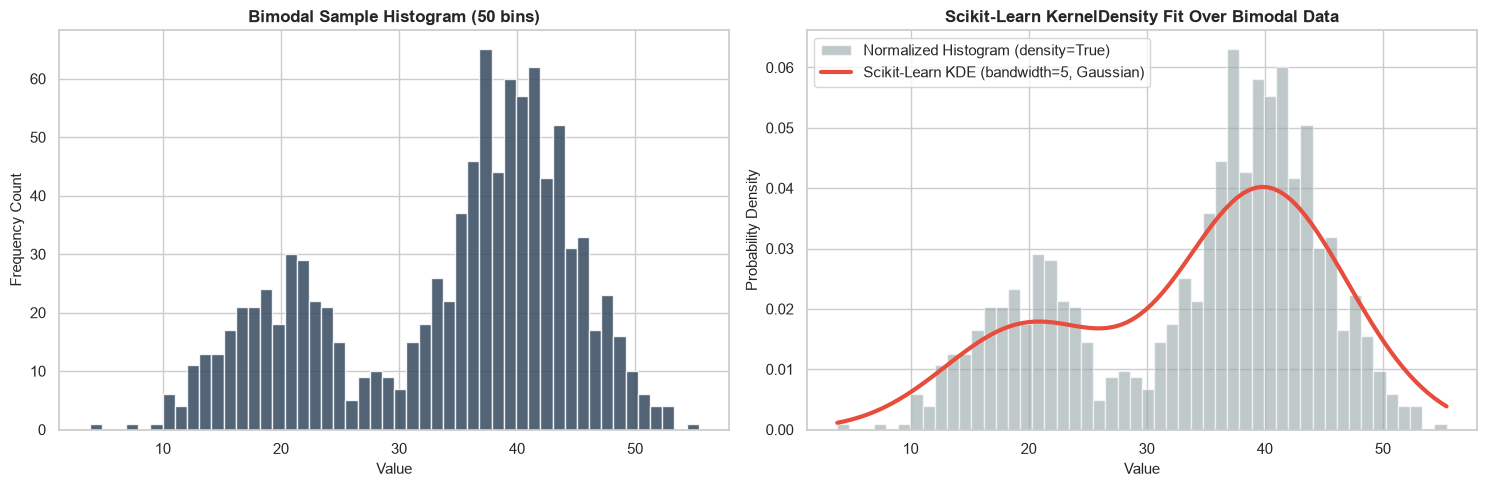

In [4]:
# ==============================================================================
# DEMONSTRATION 4: Bimodal Sample & Scikit-Learn KernelDensity Estimation
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KernelDensity

# 1. Generate bimodal mixture sample
np.random.seed(42)
sample1 = np.random.normal(loc=20, scale=5, size=300)
sample2 = np.random.normal(loc=40, scale=5, size=700)
sample = np.hstack((sample1, sample2))

print("First 5 elements of generated bimodal sample:")
print(sample[:5])

# 2. Reshape for Scikit-Learn (expects 2D array: (n_samples, n_features))
sample_2d = sample.reshape((len(sample), 1))

# 3. Build and train KernelDensity model
model = KernelDensity(bandwidth=5, kernel='gaussian')
model.fit(sample_2d)

# 4. Generate evaluation points across the domain
values = np.linspace(sample.min(), sample.max(), 100)
values_2d = values.reshape((len(values), 1))

# 5. Compute density estimates
# NOTE: score_samples() returns the log-density: ln(f(x)) to prevent numerical underflow
log_densities = model.score_samples(values_2d)
probabilities = np.exp(log_densities)  # Invert logarithm to recover actual density

# 6. Plotting the results
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Raw Histogram with 50 bins showing bimodality
axes[0].hist(sample, bins=50, color='#34495e', edgecolor='white', alpha=0.85)
axes[0].set_title('Bimodal Sample Histogram (50 bins)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Value', fontsize=11)
axes[0].set_ylabel('Frequency Count', fontsize=11)

# Subplot 2: Normalized Histogram overlaid with Scikit-Learn KDE fit
axes[1].hist(sample, bins=50, density=True, color='#95a5a6', edgecolor='white', alpha=0.6, label='Normalized Histogram (density=True)')
axes[1].plot(values, probabilities, color='#e74c3c', linewidth=3, label='Scikit-Learn KDE (bandwidth=5, Gaussian)')
axes[1].set_title('Scikit-Learn KernelDensity Fit Over Bimodal Data', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Value', fontsize=11)
axes[1].set_ylabel('Probability Density', fontsize=11)
axes[1].legend()

plt.tight_layout()
plt.show()



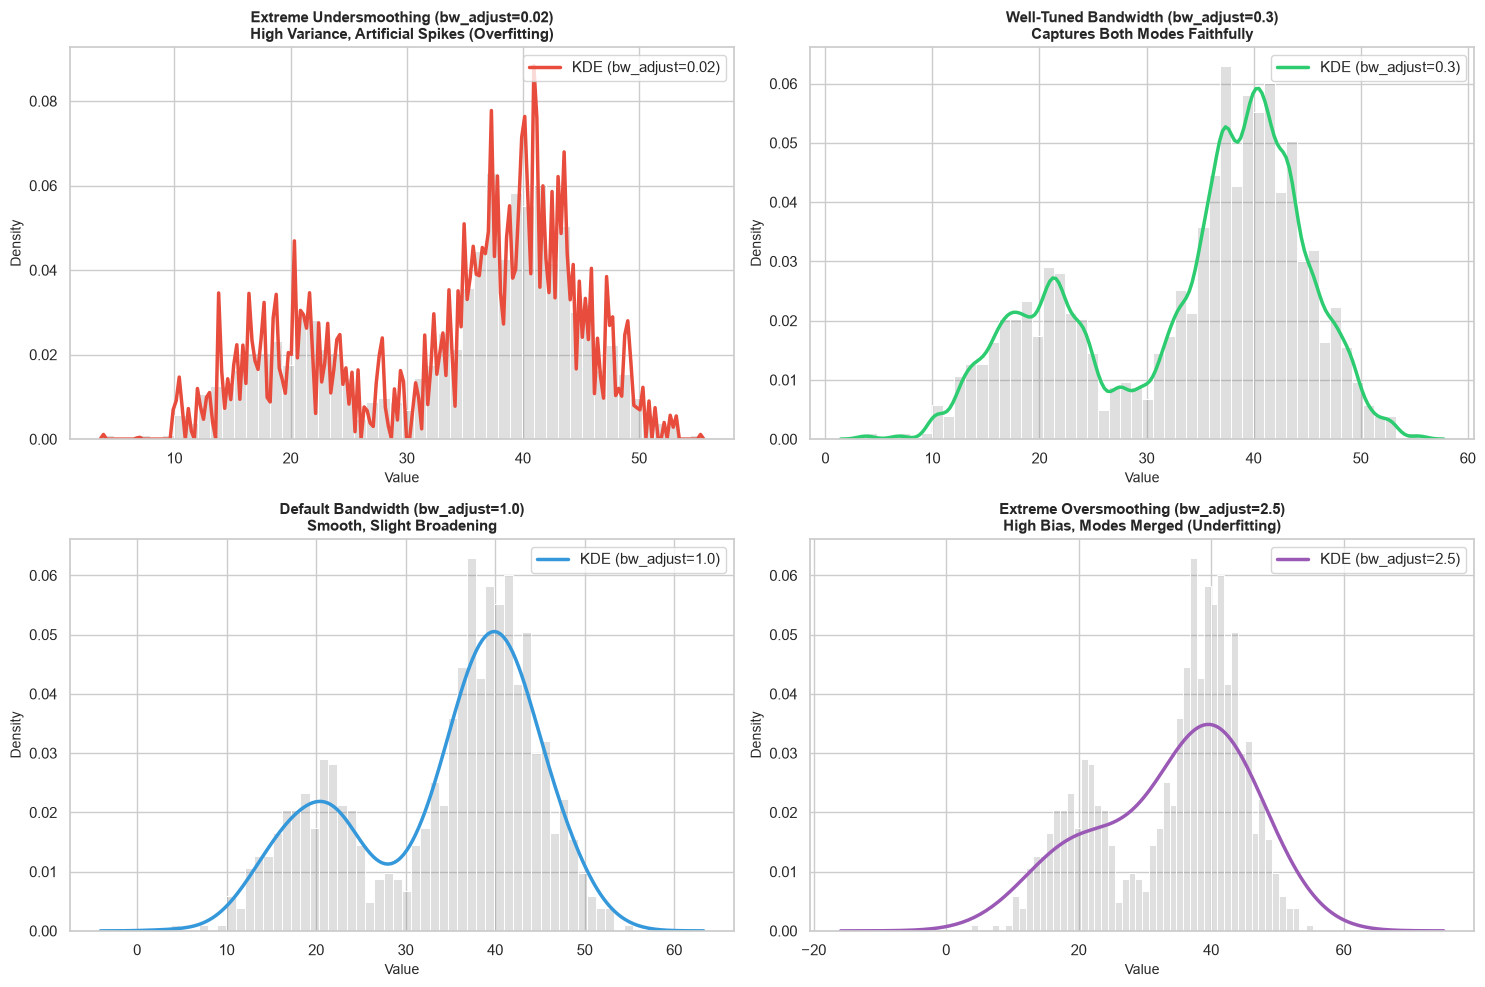

In [5]:
# ==============================================================================
# DEMONSTRATION 5: Bandwidth Tuning - Undersmoothing vs Oversmoothing
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Visualizing the impact of bw_adjust in Seaborn
# bw_adjust is a scaling multiplier for the default bandwidth rule (Silverman's / Scott's)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
bandwidth_factors = [0.02, 0.3, 1.0, 2.5]
titles = [
    'Extreme Undersmoothing (bw_adjust=0.02)\nHigh Variance, Artificial Spikes (Overfitting)',
    'Well-Tuned Bandwidth (bw_adjust=0.3)\nCaptures Both Modes Faithfully',
    'Default Bandwidth (bw_adjust=1.0)\nSmooth, Slight Broadening',
    'Extreme Oversmoothing (bw_adjust=2.5)\nHigh Bias, Modes Merged (Underfitting)'
]
colors = ['#e74c3c', '#2ecc71', '#3498db', '#9b59b6']

for ax, bw, title, color in zip(axes.flatten(), bandwidth_factors, titles, colors):
    sns.histplot(sample, bins=50, stat='density', alpha=0.25, color='gray', edgecolor=None, ax=ax)
    sns.kdeplot(sample.reshape(1000), bw_adjust=bw, ax=ax, color=color, linewidth=2.5, label=f'KDE (bw_adjust={bw})')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Value', fontsize=10)
    ax.set_ylabel('Density', fontsize=10)
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()



<a id="module-10"></a>
# Module 10: Practical ML Use Case 1: Iris Dataset (Feature Discriminability & Class Separation)

---

### 🎯 The Classic Interview Question
> **"How do you use univariate and bivariate KDE plots during feature selection? How can KDE reveal which features best separate classes in a classification problem?"**

---

### 💡 The 30-Second Interview Answer
> *"During Exploratory Data Analysis (EDA), we plot class-conditional KDEs: $P(X \mid Y = c)$ across target categories (`hue`).  
> 1. **High Distributional Overlap:** Indicates poor feature discriminability. A classifier relying on this feature will suffer a high **Bayes Error Rate** (e.g., Iris `sepal_width`).
> 2. **Low or Zero Distributional Overlap:** Indicates an exceptional feature for classification. If class distributions are completely disjoint, a simple decision boundary can achieve near 100% accuracy (e.g., Iris `petal_length` and `petal_width` for *Setosa*).
> 
> Bivariate joint KDEs (`sns.jointplot(..., kind='kde')`) further reveal non-linear dependencies, correlations, and multi-modal clustering within classes."*

---

### 🔬 Feature Evaluation on the Iris Dataset
The Iris dataset contains measurements of 150 iris flowers from 3 species: *Setosa*, *Versicolor*, and *Virginica*.
By inspecting the KDE for all 4 features:
* **Sepal Length & Sepal Width:** Show broad overlap between all three species. Sepal width is particularly uninformative because all three species share nearly identical means ($pprox 3.0$ cm).
* **Petal Length & Petal Width:** Show a dramatic bimodal/multimodal split. The *Setosa* distribution is completely detached with a large gap from the other two species, making petal dimensions the most important features in tree-based and linear models alike.



--- Iris Dataset Head ---
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


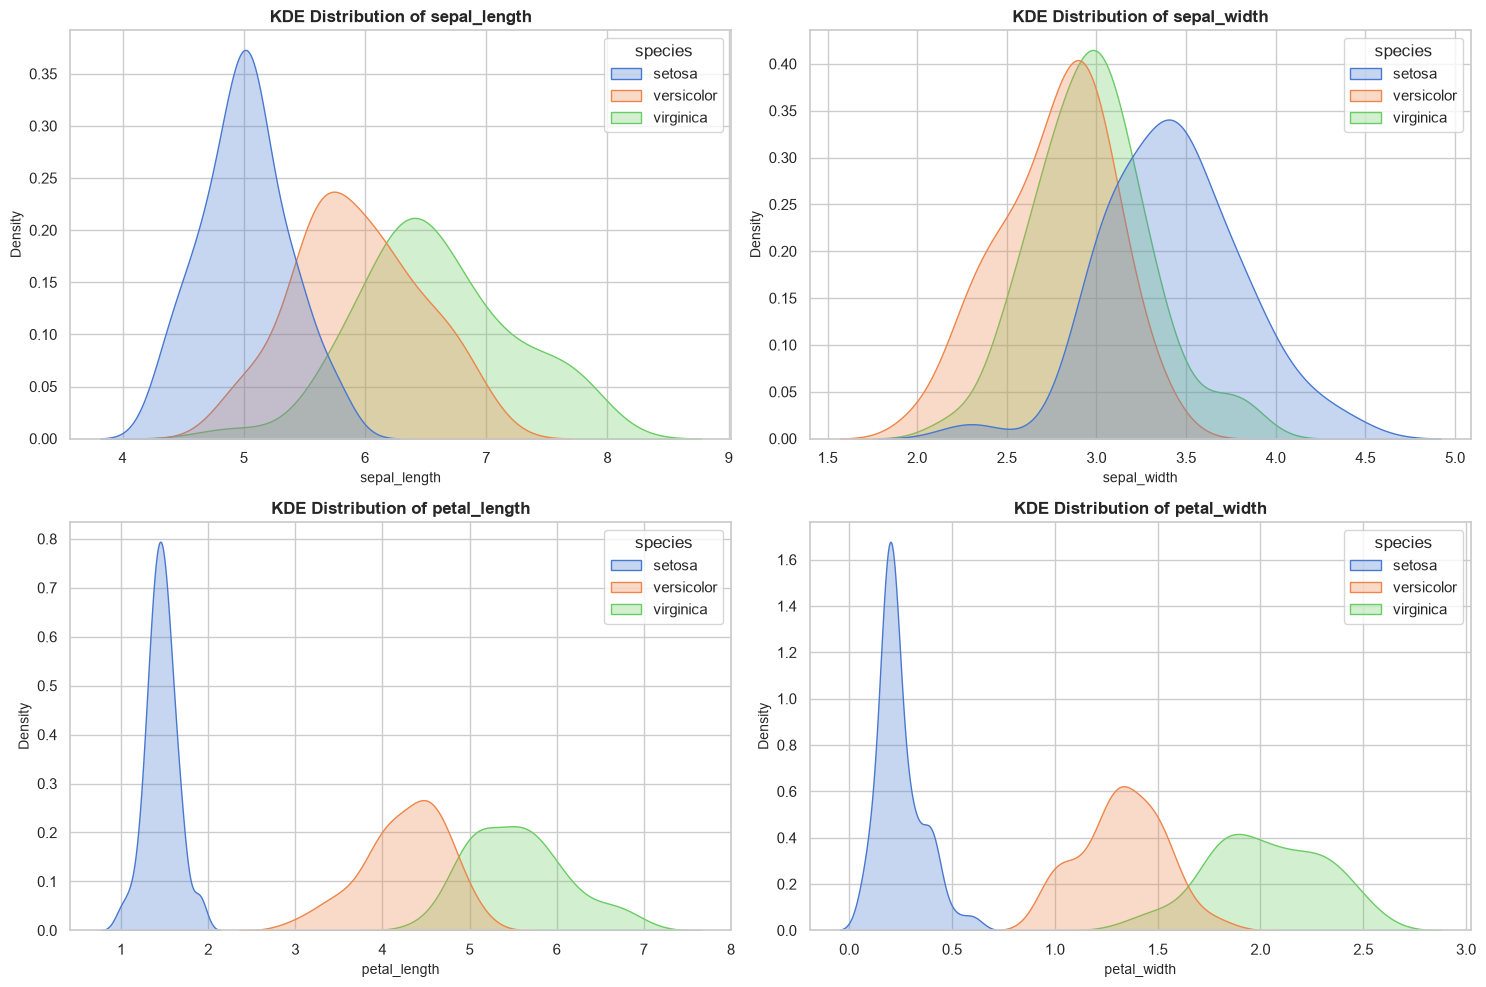


Key Insight:
Petal length and petal width are the most critical features because they completely
separate the Setosa species with ZERO distributional overlap and minimal overlap between Versicolor and Virginica!


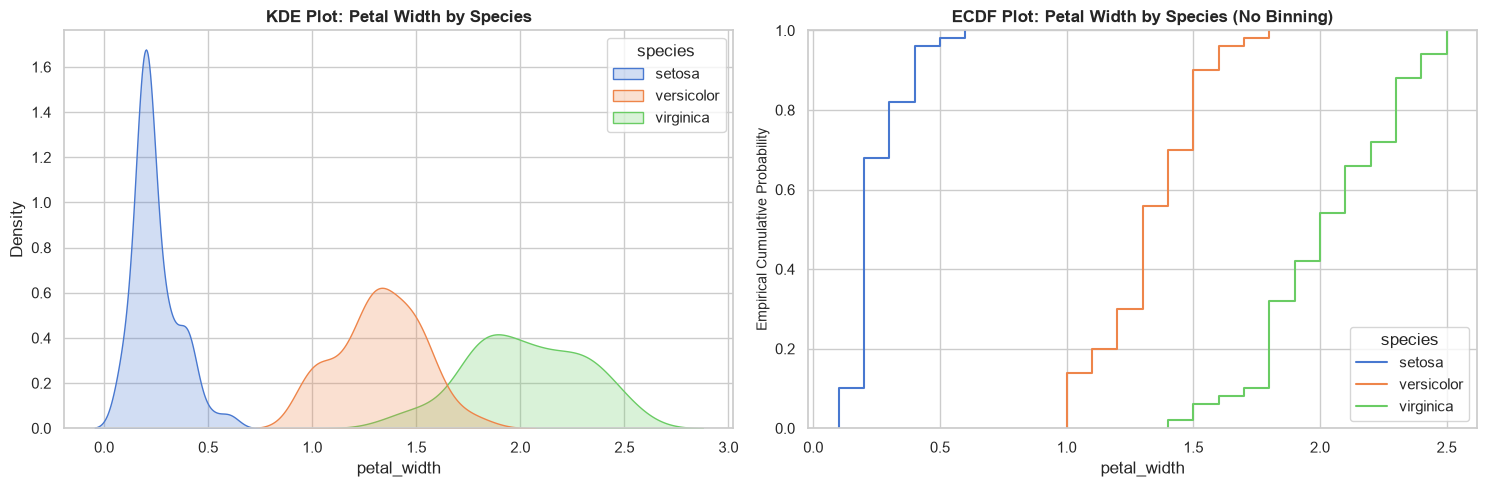

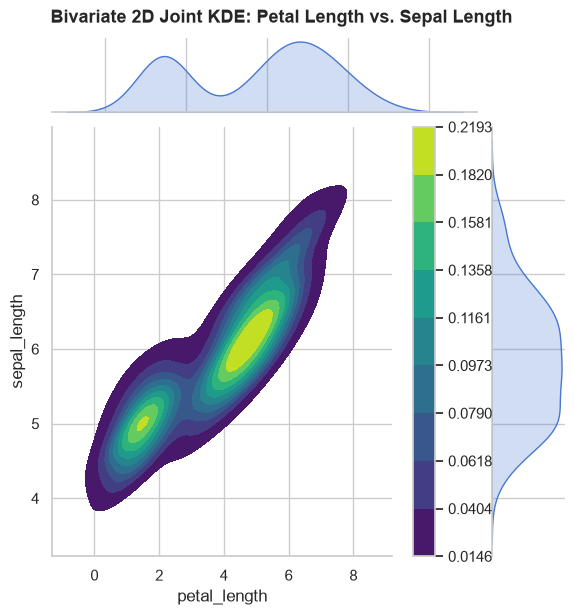

In [6]:
# ==============================================================================
# DEMONSTRATION 6: Iris Dataset Feature Discriminability & Class Separation
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = sns.load_dataset('iris')
print("--- Iris Dataset Head ---")
print(df.head())

# 1. Plot KDE for all four features by species
features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, feature in zip(axes.flatten(), features):
    sns.kdeplot(data=df, x=feature, hue='species', ax=ax, fill=True, alpha=0.3)
    ax.set_title(f'KDE Distribution of {feature}', fontsize=12, fontweight='bold')
    ax.set_xlabel(feature, fontsize=10)
    ax.set_ylabel('Density', fontsize=10)

plt.tight_layout()
plt.show()

# 2. Key Diagnostic: Petal dimensions separate Setosa flowers completely
print("\nKey Insight:")
print("Petal length and petal width are the most critical features because they completely")
print("separate the Setosa species with ZERO distributional overlap and minimal overlap between Versicolor and Virginica!")

# 3. Visualizing petal_width KDE and ECDF side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.kdeplot(data=df, x='petal_width', hue='species', ax=axes[0], fill=True)
axes[0].set_title('KDE Plot: Petal Width by Species', fontsize=12, fontweight='bold')

sns.ecdfplot(data=df, x='petal_width', hue='species', ax=axes[1])
axes[1].set_title('ECDF Plot: Petal Width by Species (No Binning)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Empirical Cumulative Probability', fontsize=10)

plt.tight_layout()
plt.show()

# 4. Joint KDE: Bivariate Relationship between Petal Length and Sepal Length
g = sns.jointplot(data=df, x="petal_length", y="sepal_length", kind="kde", fill=True, cbar=True, cmap='viridis')
g.fig.suptitle('Bivariate 2D Joint KDE: Petal Length vs. Sepal Length', y=1.02, fontsize=13, fontweight='bold')
plt.show()



<a id="module-11"></a>
# Module 11: Practical ML Use Case 2: Titanic Dataset (Diagnostics, Skewness, Kurtosis & Outliers)

---

### 🎯 The Classic Interview Question
> **"What does Kurtosis actually measure? Why is the common definition of 'peakedness' a myth, and how is kurtosis used with the 3-Sigma rule for outlier detection?"**

---

### 💡 The 30-Second Interview Answer
> *"**Kurtosis measures TAILEDNESS (outlier propensity), NOT PEAKEDNESS!**  
> The idea that kurtosis measures how 'sharp' or 'tall' the peak is, is a persistent statistical myth.
> 
> Mathematically, kurtosis is the fourth standardized central moment:  
> $$\kappa = \frac{\mathbb{E}[(X - \mu)^4]}{\sigma^4}$$
> 
> Because deviations from the mean are raised to the **fourth power**:
> * Points near the peak $(|x - \mu| < 1)$ contribute negligible amounts (e.g., $0.1^4 = 0.0001$).
> * Points in the tails $(|x - \mu| > 3)$ contribute astronomically (e.g., $4^4 = 256$, $5^4 = 625$).
> 
> Therefore, tail values completely dominate kurtosis. A high-kurtosis distribution has **heavy, fat tails** and a higher risk of extreme outliers, regardless of whether its peak is sharp, flat, or bimodal."*

---

### 🔬 Deep Dive: Tailedness vs. Peakedness & Kurtosis Types

```
  KURTOSIS CLASSIFICATION
  ┌────────────────────────────────────────────────────────────────────────┐
  │ 1. Leptokurtic (κ > 3, Excess > 0): Heavy tails, high outlier risk     │
  │ 2. Mesokurtic  (κ = 3, Excess = 0): Normal Gaussian distribution       │
  │ 3. Platykurtic (κ < 3, Excess < 0): Light/thin tails, few outliers     │
  └────────────────────────────────────────────────────────────────────────┘
```

#### Comparison: Heavy Tails vs Light Tails
| Feature | High Kurtosis (Leptokurtic) | Low Kurtosis (Platykurtic) |
| :--- | :--- | :--- |
| **Tail Behavior** | Heavy / Fat tails (Frequent extreme outliers) | Light / Thin tails (Bounded or rare outliers) |
| **Risk Profile** | High tail risk (Black Swan events, financial crashes) | Low tail risk (Predictable bounds) |
| **Peak Shape** | Can be sharp, flat, or even bimodal! | Can be sharp, flat, or uniform |
| **Canonical Example** | Student's $t$-distribution, Cauchy, stock market returns | Uniform distribution, Wigner semicircle |

#### Fisher's vs. Pearson's Definition (The -3 Trap!):
* **Pearson's Kurtosis:** Raw fourth standardized moment: $\kappa_{\text{normal}} = 3$.
* **Fisher's Excess Kurtosis:** $\kappa_{\text{excess}} = \kappa - 3$, so that a Gaussian distribution has an excess kurtosis of exactly **$0.0$**.
* ⚠️ **The Senior Interview Trap:** In Python, both `scipy.stats.kurtosis(..., fisher=True)` and `pandas.Series.kurtosis()` **already compute Fisher's excess kurtosis** (they have already subtracted 3). Candidates who do `df['col'].kurtosis() - 3` end up subtracting 3 **twice**, producing an erroneous negative number!

#### The 3-Sigma Rule (Empirical Rule) for Outlier Detection:
In a Gaussian distribution:
* $P(\mu - \sigma \le X \le \mu + \sigma) \approx 68.27\%$
* $P(\mu - 2\sigma \le X \le \mu + 2\sigma) \approx 95.45\%$
* $P(\mu - 3\sigma \le X \le \mu + 3\sigma) \approx 99.73\%$
Any observation lying outside $[\mu - 3\sigma, \mu + 3\sigma]$ represents a statistically extreme event ($< 0.27\%$ probability).



--- Titanic Dataset Head ---
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450

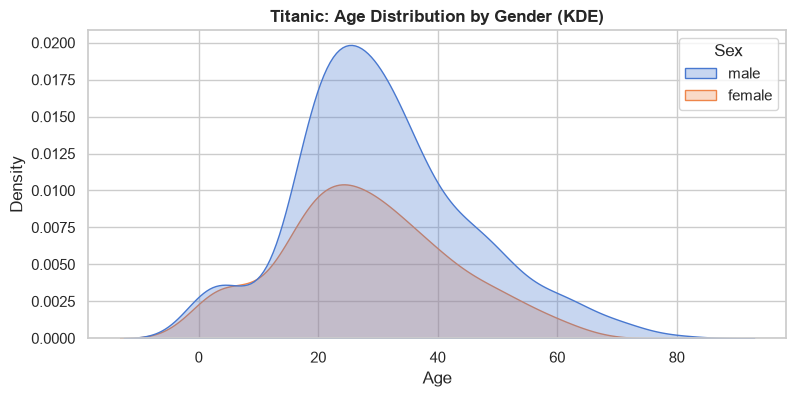

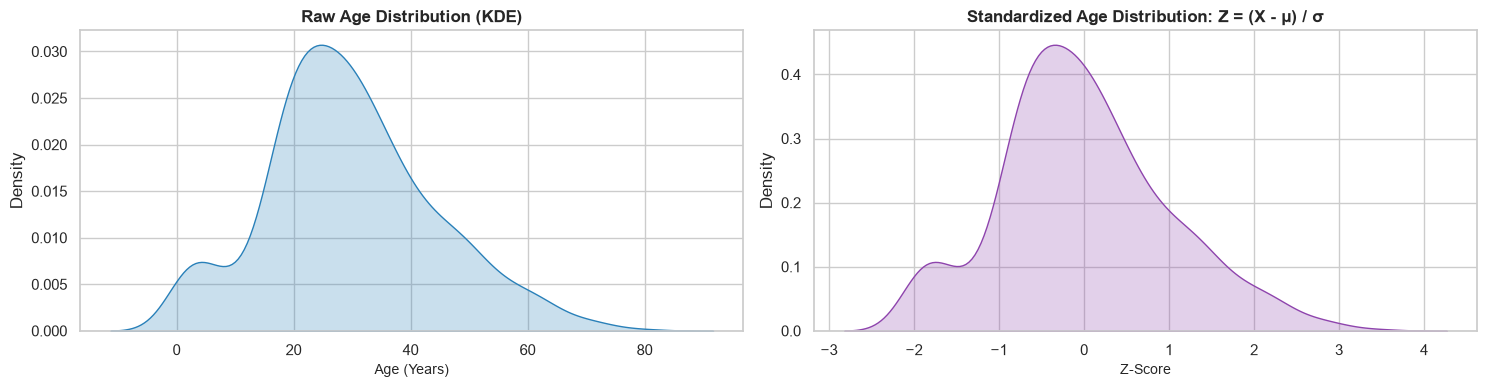

Age Skewness (Pandas): 0.389108
Interpretation: Moderate positive skew (pulled slightly to the right).

--- Kurtosis Diagnostic Analysis ---
Raw 4th Standardized Moment (Pearson Kurtosis): 3.168637
Manual Excess Kurtosis (Fourth Moment - 3):     0.168637
Scipy Excess Kurtosis (fisher=True):             0.168637
Pandas Series Kurtosis:                         0.178274

--- Senior Interview Trap Note ---
Both scipy (fisher=True) and pandas kurtosis already subtract 3.0 by default!
If you subtract 3 again from pandas kurtosis: 0.178274 - 3 = -2.821726
This results in subtracting 3 twice!

--- 3-Sigma Outlier Thresholds ---
Mean Age (μ): 29.70 years | Std Dev (σ): 14.53 years
Upper 3-Sigma Limit (μ + 3σ): 73.2786 years
Lower 3-Sigma Limit (μ - 3σ): -13.8804 years

Passengers older than 73 years (Found: 2):
     PassengerId  Survived  Pclass                                  Name  \
630          631         1       1  Barkworth, Mr. Algernon Henry Wilson   
851          852         0       3

In [7]:
# ==============================================================================
# DEMONSTRATION 7: Titanic Dataset - Standardization, Skewness, Kurtosis & Outliers
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kurtosis

# Load dataset (URL with local workspace fallback)
try:
    titanic = pd.read_csv('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv')
except Exception:
    titanic = pd.read_csv('STATISTICS/titanic.csv')

print("--- Titanic Dataset Head ---")
print(titanic.head())

# 1. Age distribution by Gender (Sex)
plt.figure(figsize=(9, 4))
sns.kdeplot(data=titanic, x='Age', hue='Sex', fill=True, alpha=0.3)
plt.title('Titanic: Age Distribution by Gender (KDE)', fontsize=12, fontweight='bold')
plt.show()

# 2. Overall Age KDE and Standardized Age KDE
age_clean = titanic['Age'].dropna()
x_standardized = (titanic['Age'] - titanic['Age'].mean()) / titanic['Age'].std()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.kdeplot(titanic['Age'], ax=axes[0], color='#2980b9', fill=True)
axes[0].set_title('Raw Age Distribution (KDE)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Age (Years)', fontsize=10)

sns.kdeplot(x_standardized, ax=axes[1], color='#8e44ad', fill=True)
axes[1].set_title('Standardized Age Distribution: Z = (X - μ) / σ', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Z-Score', fontsize=10)
plt.tight_layout()
plt.show()

# 3. Skewness
age_skew = titanic['Age'].skew()
print(f"Age Skewness (Pandas): {age_skew:.6f}")
print("Interpretation: Moderate positive skew (pulled slightly to the right).")

# 4. Kurtosis In-Depth: Manual vs Scipy vs Pandas
mean_age = age_clean.mean()
std_age = age_clean.std(ddof=0)  # Population std for moment calculation
manual_fourth_moment = np.mean((age_clean - mean_age)**4) / (std_age**4)
manual_excess_kurtosis = manual_fourth_moment - 3.0

scipy_excess_kurt = kurtosis(age_clean, fisher=True)
pandas_kurt = titanic.loc[:, 'Age'].kurtosis()

print("\n--- Kurtosis Diagnostic Analysis ---")
print(f"Raw 4th Standardized Moment (Pearson Kurtosis): {manual_fourth_moment:.6f}")
print(f"Manual Excess Kurtosis (Fourth Moment - 3):     {manual_excess_kurtosis:.6f}")
print(f"Scipy Excess Kurtosis (fisher=True):             {scipy_excess_kurt:.6f}")
print(f"Pandas Series Kurtosis:                         {pandas_kurt:.6f}")

print("\n--- Senior Interview Trap Note ---")
print("Both scipy (fisher=True) and pandas kurtosis already subtract 3.0 by default!")
print(f"If you subtract 3 again from pandas kurtosis: {pandas_kurt:.6f} - 3 = {pandas_kurt - 3:.6f}")
print("This results in subtracting 3 twice!")

# 5. Outlier Detection using the 3-Sigma Rule (Empirical Rule)
mu = titanic['Age'].mean()
sigma = titanic['Age'].std()
upper_limit = mu + 3 * sigma
lower_limit = mu - 3 * sigma

print("\n--- 3-Sigma Outlier Thresholds ---")
print(f"Mean Age (μ): {mu:.2f} years | Std Dev (σ): {sigma:.2f} years")
print(f"Upper 3-Sigma Limit (μ + 3σ): {upper_limit:.4f} years")
print(f"Lower 3-Sigma Limit (μ - 3σ): {lower_limit:.4f} years")

outliers = titanic[titanic['Age'] > 73]
print(f"\nPassengers older than 73 years (Found: {len(outliers)}):")
print(outliers[['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'Fare', 'Cabin']])



<a id="module-12"></a>
# Module 12: Master Interview Cheat Sheet & Rapid-Fire Technical Q&A

---

### ⚡ 10 High-Frequency Technical Interview Questions & Model Answers

#### Q1: Can a PDF value be greater than 1? Can a CDF value be greater than 1?
> **Answer:** **Yes for PDF, absolutely No for CDF.**  
> A continuous PDF represents a **density** (probability per unit interval), not an absolute probability. For any distribution concentrated over an interval of width $< 1$ (such as $\text{Uniform}(0, 0.2)$ where $f(x) = 5$, or a Normal distribution with $\sigma < 0.3989$), the PDF exceeds 1. In contrast, the CDF represents $P(X \le x)$, which is an actual cumulative probability strictly bounded by Kolmogorov's axioms to $[0, 1]$.

#### Q2: What is the difference between Probability and Likelihood?
> **Answer:**  
> * **Probability:** Measures the chance of observing different data outcomes $x$, given **fixed parameter values** $\theta$: $P(X = x \mid \theta)$. The integral over all possible $x$ equals 1.
> * **Likelihood:** Measures the plausibility of different candidate parameter values $\theta$, given **fixed observed data** $x$: $L(\theta \mid x) = f(x \mid \theta)$. The integral over all $\theta$ is generally NOT 1.

#### Q3: Why does $P(X = c) = 0$ for continuous distributions?
> **Answer:** Because the continuous real line contains an uncountably infinite number of points. If every point had non-zero probability, the sum would be infinite. In measure theory, a single point has Lebesgue measure zero, meaning $\int_c^c f(x)dx = 0$. Probability is only non-zero over intervals of positive length.

#### Q4: What does the bandwidth parameter $h$ in KDE control?
> **Answer:** Bandwidth $h$ controls the smoothing scale and governs the **bias-variance tradeoff**. A small $h$ undersmooths (low bias, high variance, noisy artificial spikes). A large $h$ oversmooths (high bias, low variance, blurring distinct modes together).

#### Q5: Why is the Epanechnikov kernel considered optimal?
> **Answer:** The Epanechnikov kernel minimizes the **Asymptotic Mean Integrated Squared Error (AMISE)** among all valid probability kernels. However, Gaussian kernels are more commonly used in practice because they are infinitely differentiable ($C^\infty$), producing perfectly smooth curves.

#### Q6: Why does Kurtosis measure tailedness and NOT peakedness?
> **Answer:** Because the formula $\mathbb{E}[(X - \mu)^4]/\sigma^4$ raises deviations to the 4th power. Values near the mean contribute infinitesimally (e.g., $0.1^4 = 0.0001$), while extreme tail deviations contribute massively ($5^4 = 625$). The tail behavior completely dominates the moment.

#### Q7: When would you prefer ECDF over KDE for Exploratory Data Analysis?
> **Answer:** ECDF is preferred when you want an **unbiased, non-parametric view** of the data without tuning any hyperparameters. KDE requires selecting a bandwidth $h$, which can accidentally introduce artificial modes or hide real clusters. ECDF preserves all raw points and has guaranteed uniform convergence via the Glivenko-Cantelli theorem.

#### Q8: How does Standardization ($Z$-Score) affect the shape of a distribution?
> **Answer:** Standardization ($Z = \frac{X - \mu}{\sigma}$) is a linear/affine transformation. It shifts the center to $\mu = 0$ and scales the dispersion to $\sigma = 1$, but **leaves Skewness, Kurtosis, and overall distributional shape completely unchanged**. It does NOT make non-normal data normal.

#### Q9: How is Kernel Density Estimation used in Unsupervised Anomaly Detection?
> **Answer:** We fit a KDE model on normal training data. For any new test point $x^*$, we evaluate its estimated density $\hat{f}(x^*)$. If $\hat{f}(x^*) < \tau$ (where $\tau$ is a density threshold corresponding to, say, the 1st percentile), the observation falls in a low-density region and is flagged as an anomaly.

#### Q10: What is the relationship between the CDF and the p-value in hypothesis tests?
> **Answer:** The p-value is the probability of observing a test statistic at least as extreme as the observed value under the null hypothesis $H_0$. For a one-tailed test with test statistic $T$, the p-value is computed directly from the CDF: $p = 1 - F_0(T)$ (for upper-tail) or $p = F_0(T)$ (for lower-tail).

